# Modèles de mélange gaussien (GMM) from scratch

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/moncoachdata/cercle-des-experts/blob/main/ml-classique-et-deep-learning/modeles-melange-gaussien-gmm/modeles-melange-gaussien-gmm.ipynb)

📖 **Le mini-cours complet** : [Comprendre les Modèles de Mélange Gaussien (GMMs)](https://www.monshotdata.com/p/modeles-melange-gaussien-gmm)

🧭 **Le cours** : [ML classique et Deep Learning › 2.3 Clustering et réduction de dimension](https://www.monshotdata.com/mini-cours/ml-classique-et-deep-learning#h2sc23)

---

KMeans suppose des clusters ronds, de même taille, et te donne une réponse tranchée : tel point est dans tel cluster. Les modèles de mélange gaussien disent mieux : des clusters **de formes différentes** et une **probabilité** d'appartenance pour chaque point. Dans ce notebook, tu vas coder l'algorithme EM de zéro, puis vérifier que tu retrouves le résultat de scikit-learn.

**À la fin de ce notebook, tu sauras :**

- voir où KMeans échoue sur des clusters allongés, et pourquoi un GMM s'en sort mieux ;
- implémenter l'algorithme Espérance-Maximisation (EM) en NumPy, étape par étape ;
- valider ton implémentation contre `GaussianMixture` de scikit-learn.


### Avant de lancer

Aucun fichier externe, aucun GPU : **Exécution → Tout exécuter** (une dizaine de secondes). Les données sont simulées aléatoirement : les valeurs exactes (log-vraisemblance, moyennes) changeront à chaque exécution, et l'ordre des clusters aussi, ce qui est normal.

🧪 *Testé le 20 novembre 2026 avec Python 3.13, NumPy, scikit-learn et Matplotlib dans leurs versions de Colab.*

## 1. Mise en place

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from matplotlib.patches import Ellipse
from sklearn.mixture import GaussianMixture

sns.set()

In [2]:
colors = ['#fe7c73', '#2471A3', '#5D6D7E', '#27AE60']

## 2. Un jeu de données où KMeans va souffrir

On génère quatre clusters gaussiens **non sphériques** : deux très allongés verticalement (variance 12 sur l'axe y) et deux moins étirés (variance 3). Chaque cluster contient 600 points.

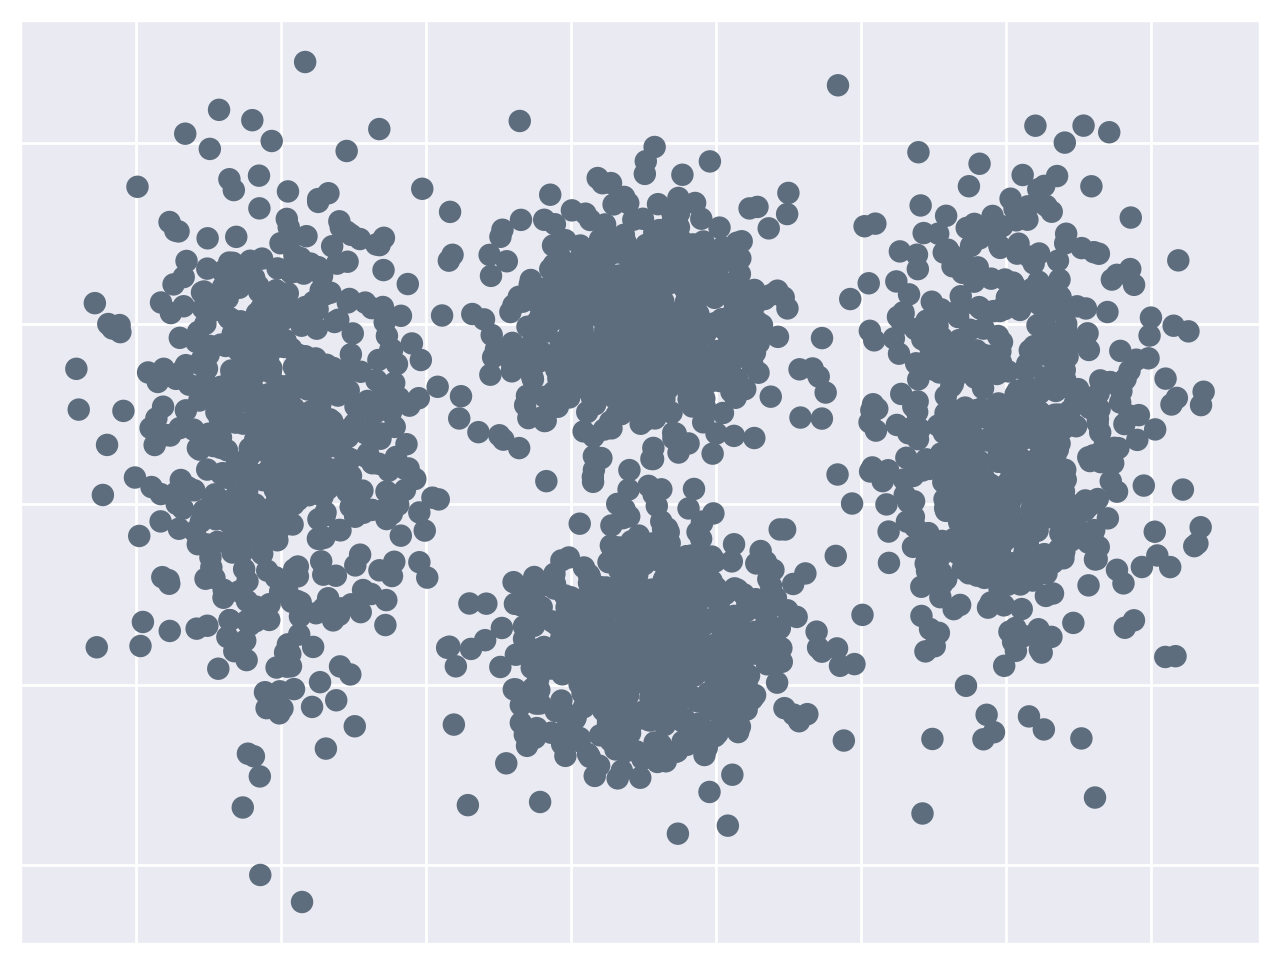

In [3]:
n_samples = 600
n_features = 2

# Créer les centres des clusters
centers = np.array([[2, 2], [7, 5], [7, -4], [12, 2]])

# Créer les matrices de covariance pour chaque cluster
cov_matrices = [
    [[1, 0], [0, 12]],
    [[1, 0], [0, 3]],
    [[1, 0], [0, 3]],
    [[1, 0], [0, 12]]
]

# Générer les données pour chaque cluster
data = []
labels = []
for i, (center, cov_matrix) in enumerate(zip(centers, cov_matrices)):
    cluster_data = np.random.multivariate_normal(center, cov_matrix, n_samples)
    data.append(cluster_data)
    labels.append(np.full(n_samples, i))

# Concaténer les données et les étiquettes
X = np.concatenate(data, axis=0)
y = np.concatenate(labels, axis=0)

# Afficher le jeu de données de blobs non-sphériques
fig, ax = plt.subplots(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=[colors[2] for i in y], s=50)
ax.set_xticklabels([])
ax.set_yticklabels([])
plt.show()

## 3. Le point de départ : KMeans

On demande à KMeans de trouver 4 clusters. Il ne regarde que les distances aux centres : les frontières qu'il trace coupent les clusters allongés au lieu de les suivre.

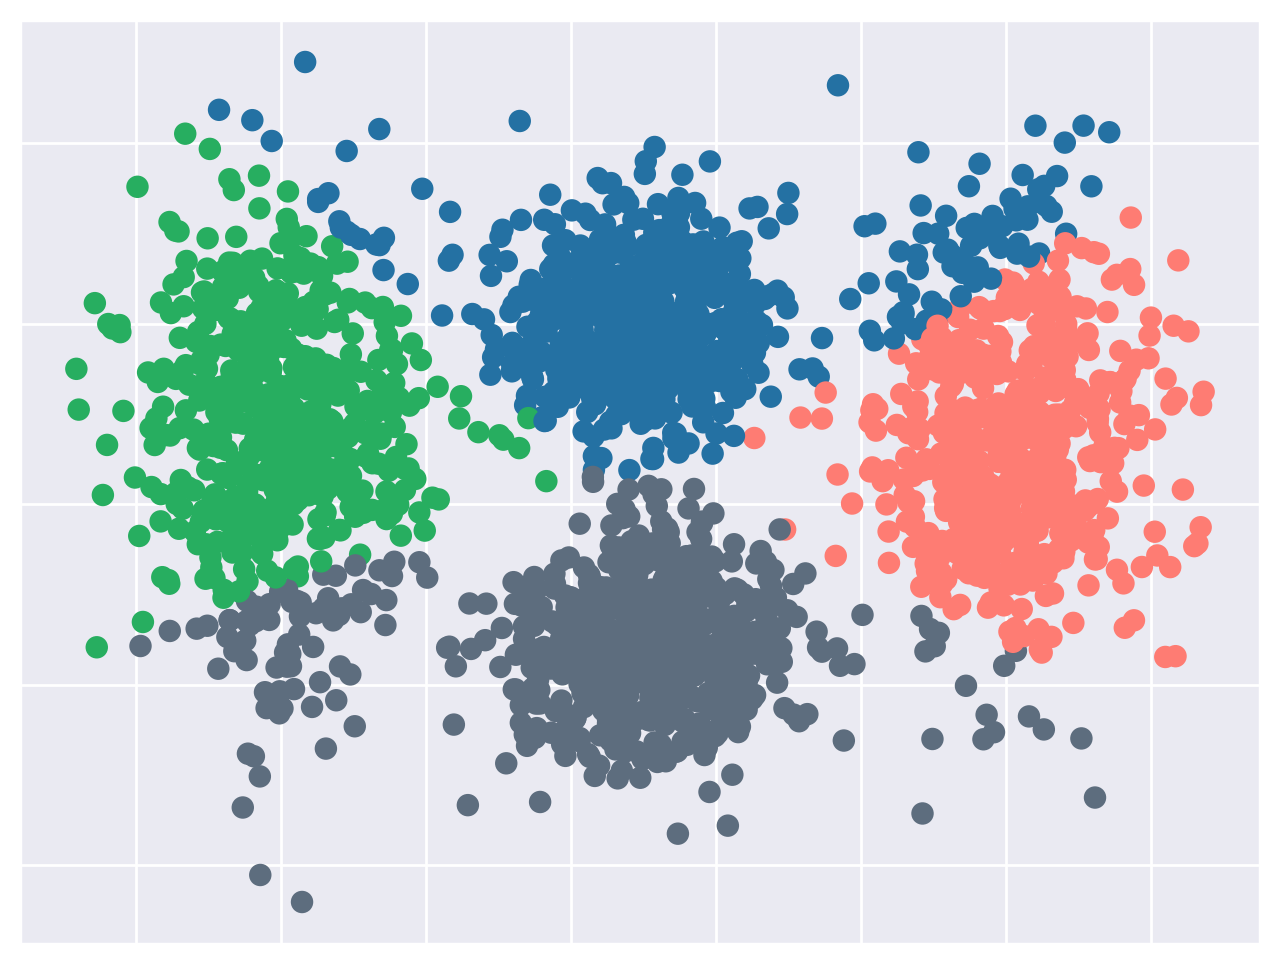

In [4]:
kmeans = KMeans(4).fit(X)

fig, ax = plt.subplots(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=[colors[i] for i in kmeans.labels_], s=50)
ax.set_xticklabels([])
ax.set_yticklabels([])
plt.show()

## 4. Un GMM codé à la main

Un GMM modélise les données comme un mélange de gaussiennes. Chaque cluster *k* a trois paramètres : son poids π_k, sa moyenne μ_k et sa covariance Σ_k. L'algorithme EM les apprend en alternant deux étapes jusqu'à convergence.

### 4.1 Une fonction qui calcule la densité gaussienne multivariée

Brique de base : la densité de la loi normale multivariée en chaque point.

In [5]:
def gaussian(X, mu, cov):
    n = X.shape[1]
    diff = (X - mu).T
    return np.diagonal(1 / ((2 * np.pi) ** (n / 2) * np.linalg.det(cov) ** 0.5) * np.exp(-0.5 * np.dot(np.dot(diff.T, np.linalg.inv(cov)), diff))).reshape(-1, 1)

### 4.2 Initialisation avec KMeans

EM est sensible à son point de départ. On initialise les moyennes avec les centres de KMeans, les poids avec 1/K et les covariances avec la matrice identité.

In [6]:
def run_kmeans(X, k):
    clusters = []
    
    # Exécuter KMeans
    kmeans = KMeans(k).fit(X)
    
    # Obtenir les centres des clusters
    mu_k = kmeans.cluster_centers_
    
    # Stocker les paramètres des clusters
    for i in range(k):
        
        param_dict = {}
        param_dict['pi_k'] = 1.0 / k
        param_dict['mu_k'] = mu_k[i]
        param_dict['cov_k'] = np.identity(X.shape[1], dtype=np.float64)
        
        clusters.append(param_dict)        
        
    return clusters

### 4.3 Étape d'espérance (E)

Pour chaque point et chaque cluster, on calcule la **responsabilité** γ_ik : la probabilité que le point *i* ait été généré par le cluster *k*, avec les paramètres actuels. C'est ce qui donne des probabilités d'appartenance plutôt qu'une étiquette dure.

In [7]:
def run_exp_step(X, clusters):

    N = X.shape[0]  # points de données
    K = len(clusters)  # nombre de clusters
        
    # gamma pour tous les points
    gamma_ik = np.zeros((N, K))
    
    # calculer gamma des points de données sur tous les clusters
    for k, cluster in enumerate(clusters):
    
        # obtenir les dernières estimations
        pi_k = cluster['pi_k']
        mu_k = cluster['mu_k']
        cov_k = cluster['cov_k']
    
        # trouver gamma avec les dernières estimations
        gamma_ik[:, k] = (pi_k * gaussian(X, mu_k, cov_k)).ravel()
    
    # dénominateur du calcul de gamma
    gamma_sum = np.sum(gamma_ik, 1)
    
    # calcul final de gamma
    gamma_ik /= np.expand_dims(gamma_sum, 1)
    
    return gamma_ik, gamma_sum

### 4.4 Étape de maximisation (M)

On met à jour les paramètres de chaque cluster en les pondérant par les responsabilités : nouveau poids, nouvelle moyenne, nouvelle covariance.

In [8]:
def run_maxi_step(X, clusters, gamma_ik):
    
    N = X.shape[0]  # total de points de données
    
    # mettre à jour les valeurs des paramètres pour tous les clusters
    for k, cluster in enumerate(clusters):
    
        # gamma de tous les points 
        # correspondant au cluster k
        gamma_k = np.expand_dims(gamma_ik[:, k], 1)
        
        # somme de gamma pour tous les points
        N_k = np.sum(gamma_k, axis=0)
        
        # mettre à jour les paramètres
        pi_k = N_k / N
        mu_k = np.sum(gamma_k * X, axis=0) / N_k
        cov_k = (gamma_k * (X - mu_k)).T @ (X - mu_k) / N_k
        
        # mise à jour dans le dictionnaire des paramètres
        cluster['pi_k'] = pi_k
        cluster['mu_k'] = mu_k
        cluster['cov_k'] = cov_k
        
    return clusters

### 4.5 La log-vraisemblance

Ce qu'EM cherche à maximiser. Elle ne peut que monter d'une itération à l'autre : c'est notre indicateur de convergence.

In [9]:
def find_log_likelihood(gamma_sum):
    
    return np.sum(np.log(gamma_sum))

### 4.6 L'algorithme complet

On enchaîne : initialisation avec KMeans, puis E, M et calcul de la vraisemblance, à chaque itération.

In [10]:
def run_gmm(X, n_clusters, n_epochs):
    # Exécuter KMeans
    clusters = run_kmeans(X, n_clusters)

    # Itérer
    for i in range(n_epochs):
        # exécuter l'étape d'espérance pour mettre à jour gamma
        gamma_nk, gamma_sum = run_exp_step(X, clusters)
        
        # exécuter l'étape de maximisation pour mettre à jour les paramètres
        run_maxi_step(X, clusters, gamma_nk)
        
        # trouver la vraisemblance
        likelihood = find_log_likelihood(gamma_sum)
        
        if i%10 == 0:
            print(f"Itération {i+1} --> log-vraisemblance = {likelihood:.2f}")

    # retourner les clusters finaux
    return clusters

On l'exécute sur 50 itérations. La log-vraisemblance se stabilise après une vingtaine d'itérations : l'algorithme a convergé.

In [11]:
n_clusters = 4
n_epochs = 50

clusters = run_gmm(X, n_clusters, n_epochs)

Itération 1 --> log-vraisemblance = -16016.75


Itération 11 --> log-vraisemblance = -12085.74


Itération 21 --> log-vraisemblance = -12085.74


Itération 31 --> log-vraisemblance = -12085.74


Itération 41 --> log-vraisemblance = -12085.74


## 5. La même chose avec scikit-learn

`GaussianMixture` fait tout ça en deux lignes. On trace les clusters et, pour chacun, les ellipses à 1 et 2 écarts-types : elles épousent la forme allongée des clusters.

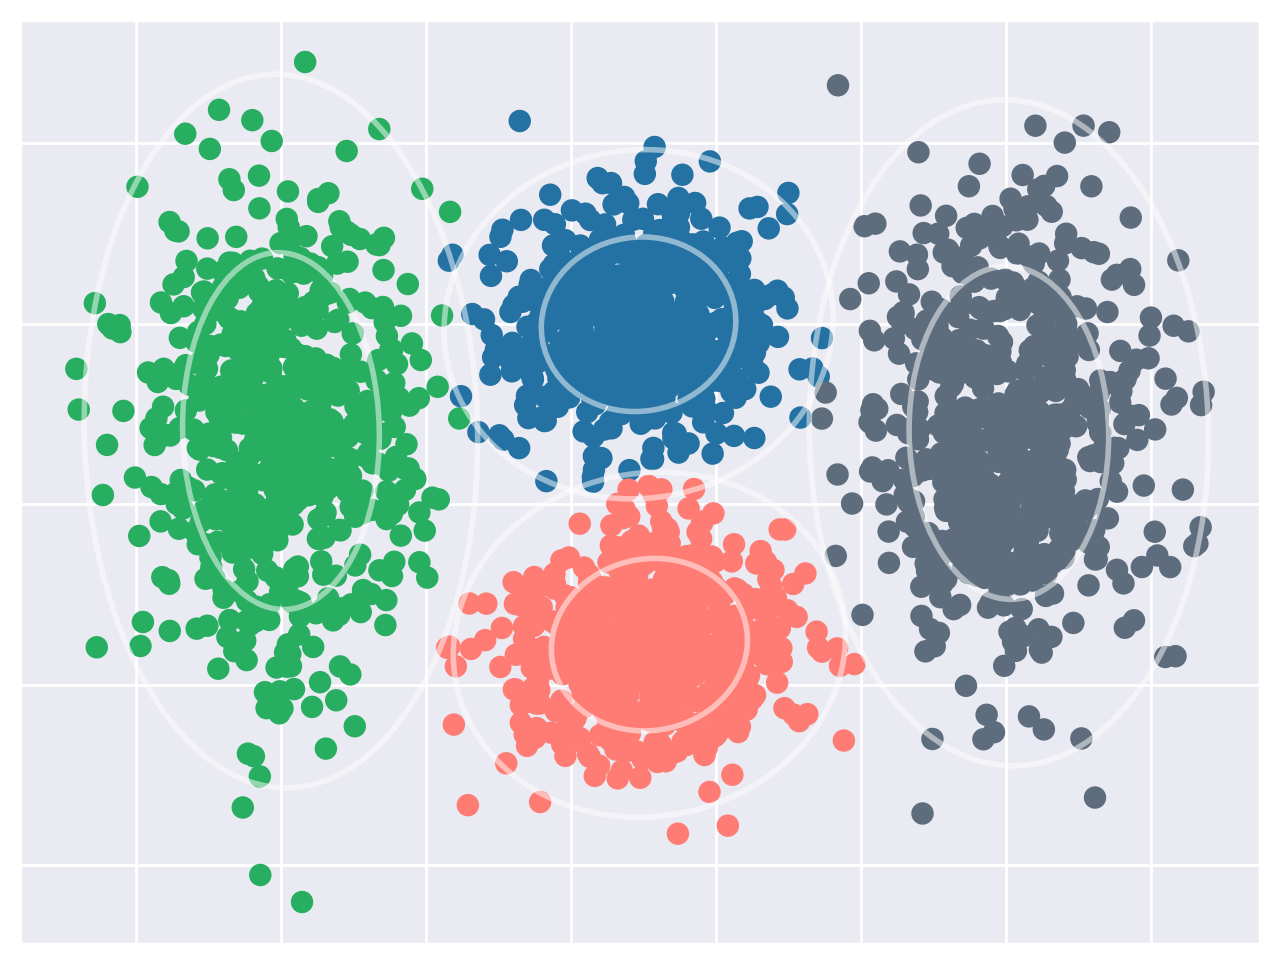

In [12]:
gmm = GaussianMixture(n_components=4, random_state=0)
gmm.fit(X)
labels = gmm.predict(X)

# # Afficher les clusters
fig, ax = plt.subplots(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=[colors[i] for i in labels], s=50)

for i, (mean, cov) in enumerate(zip(gmm.means_, gmm.covariances_)):
    v, w = np.linalg.eigh(cov)
    v = 2.0 * np.sqrt(2.0) * np.sqrt(v)
    u = w[0] / np.linalg.norm(w[0])
    angle = np.arctan(u[1] / u[0])
    angle = 180.0 * angle / np.pi

    # # Ajouter des ellipses de contour à différents écarts-types
    for std in range(1, 3):
        ell = Ellipse(mean, std * v[0], std * v[1], angle=180.0 + angle, color='gray', alpha=0.3)
        ell.set_facecolor('none')
        ell.set_edgecolor('white')
        ell.set_alpha(0.5)
        ell.set_linewidth(2)
        ax.add_artist(ell)

ax.set_xticklabels([])
ax.set_yticklabels([])       
plt.show()

### Comparaison avec notre implémentation

Les moyennes trouvées par les deux méthodes sont quasi identiques (à l'ordre des clusters près).

In [13]:
print('Moyennes retournées par sklearn :\n', gmm.means_)
print('Moyennes retournées par l\'implémentation personnalisée :\n', np.array([cluster['mu_k'].tolist() for cluster in clusters]))

## Elles sont correctes. Seul l'ordre est différent.

Moyennes retournées par sklearn :
 [[ 7.08312181 -3.89110159]
 [ 6.93362145  4.97968191]
 [12.03804575  1.97343045]
 [ 2.00431838  2.02276564]]
Moyennes retournées par l'implémentation personnalisée :
 [[12.03684713  1.97369569]
 [ 2.00601894  2.02379321]
 [ 7.08310177 -3.89105085]
 [ 6.93416299  4.98019477]]


---

## Pour aller plus loin

- [Score de silhouette vs méthode du coude : un choix évident](https://www.monshotdata.com/p/score-de-silhouette-vs-methode-du-coude) — choisir le nombre de clusters
- [MLE expliquée simplement : l’intuition que les maths ne montrent pas](https://www.monshotdata.com/p/estimation-maximum-vraisemblance) — le principe derrière l'étape M
- [Régression Logistique : Plongée dans la logique de la perte logarithmique](https://www.monshotdata.com/p/regression-logistique-perte-logarithmique) — un autre modèle appris par maximum de vraisemblance